In [ ]:
# ============================================================
# TIMEGPT - PRONÓSTICO DE RADIACIÓN SOLAR
# Serie temporal cada 15 minutos
#
# Permite seleccionar:
#   - Fecha de inicio del pronóstico
#   - Cantidad de horas a pronosticar
#   - Cantidad de días de contexto
#
# Genera:
#   - MAE
#   - RMSE
#   - sMAPE
#   - WAPE
#   - Gráfico completo
#   - Real vs predicción
#   - Error de predicción
#   - CSV de predicciones
#   - CSV de métricas
#   - TXT resumen
# ============================================================


# ============================================================
# 0. LIBRERÍAS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nixtla import NixtlaClient
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================
#
# >>> MODIFICAR PRINCIPALMENTE ESTOS TRES VALORES <<<
# ============================================================

ARCHIVO = "unificada.csv"

COLUMNA_FECHA = "fecha"

COLUMNA_OBJETIVO = "radiacion"


# ------------------------------------------------------------
# Fecha desde la cual queremos evaluar
# ------------------------------------------------------------

FECHA_INICIO_TEST = "2026-02-15 00:00:00"


# ------------------------------------------------------------
# Horizonte
#
# 6  = 6 horas
# 12 = 12 horas
# 24 = 24 horas
# 48 = 48 horas
# ------------------------------------------------------------

HORAS_PREDICCION = 168

# Historia reciente entregada a TimeGPT
DIAS_CONTEXTO = 630

# ------------------------------------------------------------
# Frecuencia
# ------------------------------------------------------------

FREQ = "15min"


# ------------------------------------------------------------
# 4 observaciones por hora
# ------------------------------------------------------------

PASOS_POR_HORA = 4


# ------------------------------------------------------------
# Horizonte automático
# ------------------------------------------------------------

H = int(
    HORAS_PREDICCION *
    PASOS_POR_HORA
)


print("=" * 65)
print("CONFIGURACIÓN DEL EXPERIMENTO TIMEGPT")
print("=" * 65)

print(
    "Fecha inicio test :",
    FECHA_INICIO_TEST
)

print(
    "Horas predicción  :",
    HORAS_PREDICCION
)

print(
    "Pasos             :",
    H
)

print(
    "Días de contexto  :",
    DIAS_CONTEXTO
)

print(
    "Frecuencia        :",
    FREQ
)

print("=" * 65)



In [ ]:

# ============================================================
# 2. API KEY DE NIXTLA
# ============================================================
#
# OPCIÓN RECOMENDADA:
#
# Guardar la API key como variable de entorno:
#
# Linux / Mac:
# export NIXTLA_API_KEY="tu_clave"
#
# Windows:
# set NIXTLA_API_KEY=tu_clave
#
# En Jupyter también podrías hacer:
#
# import os
# os.environ["NIXTLA_API_KEY"] = "tu_clave"
#
# ============================================================

API_KEY = 'nixak-0dea77cc906e018c018d8bd6071c8c6cfb754654bb3adb5585155dbbcd7ba352cbcbefd609d95044'

if not API_KEY:

    raise ValueError(
        "\nNo se encontró NIXTLA_API_KEY.\n"
        "Definí tu API key de Nixtla antes "
        "de ejecutar el script."
    )


nixtla_client = NixtlaClient(
    api_key=API_KEY
)


print("\nCliente TimeGPT creado.")



In [ ]:

# ============================================================
# 3. CARGAR LA BASE
# ============================================================

print("\n")
print("=" * 65)
print("CARGANDO BASE")
print("=" * 65)


df_original = pd.read_csv(

    ARCHIVO,

    sep=";",

    low_memory=False

)


print(
    "Dimensión original:",
    df_original.shape
)


print("\nColumnas disponibles:")

print(
    df_original.columns.tolist()
)



In [ ]:

# ============================================================
# 4. CONVERTIR FECHA
# ============================================================

df_original[COLUMNA_FECHA] = pd.to_datetime(

    df_original[COLUMNA_FECHA],

    dayfirst=True,

    errors="coerce"

)


# ============================================================
# 5. CONVERTIR RADIACIÓN A NUMÉRICO
# ============================================================

df_original[COLUMNA_OBJETIVO] = pd.to_numeric(

    df_original[COLUMNA_OBJETIVO],

    errors="coerce"

)


# ============================================================
# 6. CONSERVAR VARIABLES NECESARIAS
# ============================================================

df = df_original[
    [
        COLUMNA_FECHA,
        COLUMNA_OBJETIVO
    ]
].copy()



In [ ]:

# ============================================================
# 7. ELIMINAR FECHAS INVÁLIDAS
# ============================================================

df = df.dropna(
    subset=[COLUMNA_FECHA]
)


print(
    "\nRegistros después de eliminar fechas inválidas:",
    len(df)
)


# ============================================================
# 8. RESOLVER TIMESTAMPS DUPLICADOS
# ============================================================

duplicados = df[
    COLUMNA_FECHA
].duplicated().sum()


print(
    "\nTimestamps duplicados encontrados:",
    duplicados
)


# Si hay varias observaciones en la misma fecha/hora,
# se utiliza el promedio de radiación.

df = (

    df.groupby(
        COLUMNA_FECHA,
        as_index=False
    )[COLUMNA_OBJETIVO]

    .mean()

)


# ============================================================
# 9. ORDENAR CRONOLÓGICAMENTE
# ============================================================

df = df.sort_values(
    COLUMNA_FECHA
)


print("\nRango temporal original:")

print(
    df[COLUMNA_FECHA].min(),
    "->",
    df[COLUMNA_FECHA].max()
)


In [ ]:

# ============================================================
# 10. CREAR GRILLA EXACTA DE 15 MINUTOS
# ============================================================
#
# Esto es fundamental para TimeGPT.
#
# TimeGPT necesita:
#
# 00:00
# 00:15
# 00:30
# 00:45
# 01:00
# ...
#
# Sin timestamps faltantes.
# ============================================================

df = df.set_index(
    COLUMNA_FECHA
)


indice_completo = pd.date_range(

    start=df.index.min(),

    end=df.index.max(),

    freq=FREQ

)


df = df.reindex(
    indice_completo
)


df.index.name = COLUMNA_FECHA


print(
    "\nRegistros después de crear "
    "la grilla temporal:",
    len(df)
)


faltantes_iniciales = df[
    COLUMNA_OBJETIVO
].isna().sum()


print(
    "Valores faltantes encontrados:",
    faltantes_iniciales
)


# ============================================================
# 11. TRATAMIENTO DE VALORES FALTANTES
# ============================================================
#
# Primera etapa:
# interpolamos solamente huecos pequeños.
#
# limit=4 equivale aproximadamente a 1 hora.
# ============================================================

df[COLUMNA_OBJETIVO] = (

    df[COLUMNA_OBJETIVO]

    .interpolate(

        method="time",

        limit=4

    )

)


faltantes_intermedios = df[
    COLUMNA_OBJETIVO
].isna().sum()


print(
    "\nFaltantes después de "
    "interpolación corta:",
    faltantes_intermedios
)


# ============================================================
# 12. COMPLETAR HUECOS RESTANTES
# ============================================================
#
# TimeGPT no acepta timestamps faltantes.
#
# Para garantizar una serie completamente regular,
# completamos los huecos restantes.
# ============================================================

df[COLUMNA_OBJETIVO] = (

    df[COLUMNA_OBJETIVO]

    .interpolate(

        method="time",

        limit_direction="both"

    )

)


faltantes_finales = df[
    COLUMNA_OBJETIVO
].isna().sum()


print(
    "Faltantes finales:",
    faltantes_finales
)


In [ ]:

# ============================================================
# 13. VOLVER A DATAFRAME NORMAL
# ============================================================

df = df.reset_index()


# ============================================================
# 14. CONTROLES DE CALIDAD
# ============================================================

print("\n")
print("=" * 65)
print("CONTROL DE LA SERIE")
print("=" * 65)


print(
    "Rango:",
    df[COLUMNA_FECHA].min(),
    "->",
    df[COLUMNA_FECHA].max()
)


print(
    "\nCantidad de registros:",
    len(df)
)


print(
    "\nNaN:",
    df[COLUMNA_OBJETIVO]
    .isna()
    .sum()
)


print(
    "\nDuplicados:",
    df[COLUMNA_FECHA]
    .duplicated()
    .sum()
)


frecuencia_inferida = pd.infer_freq(
    df[COLUMNA_FECHA]
)


print(
    "\nFrecuencia inferida:",
    frecuencia_inferida
)


# ============================================================
# 15. VERIFICAR FRECUENCIA MANUALMENTE
# ============================================================

diferencias = (

    df[COLUMNA_FECHA]

    .diff()

    .dropna()

)


frecuencia_esperada = pd.Timedelta(
    minutes=15
)


problemas_frecuencia = (

    diferencias != frecuencia_esperada

).sum()


print(
    "Saltos temporales diferentes "
    "de 15 minutos:",
    problemas_frecuencia
)


if problemas_frecuencia > 0:

    raise ValueError(
        "La serie todavía presenta "
        "problemas de frecuencia."
    )


if df[COLUMNA_OBJETIVO].isna().sum() > 0:

    raise ValueError(
        "La serie todavía contiene NaN."
    )


print(
    "\nSerie regularizada correctamente."
)



In [ ]:



# ============================================================
# 16. DEFINIR PERÍODO DE EVALUACIÓN
# ============================================================

fecha_inicio = pd.Timestamp(
    FECHA_INICIO_TEST
)


fecha_fin = (

    fecha_inicio

    +

    pd.Timedelta(
        minutes=15 * (H - 1)
    )

)


print("\n")
print("=" * 65)
print("PERÍODO DE EVALUACIÓN")
print("=" * 65)


print(
    "Inicio:",
    fecha_inicio
)


print(
    "Fin:",
    fecha_fin
)


print(
    "Horizonte:",
    HORAS_PREDICCION,
    "horas"
)


print(
    "Número de pasos:",
    H
)


# ============================================================
# 17. VERIFICAR QUE EL TEST ESTÉ EN LA BASE
# ============================================================

if fecha_inicio < df[COLUMNA_FECHA].min():

    raise ValueError(
        "La fecha de inicio es anterior "
        "al comienzo de la base."
    )


if fecha_fin > df[COLUMNA_FECHA].max():

    raise ValueError(
        "El período de prueba supera "
        "el final de la base."
    )



In [ ]:

# ============================================================
# 18. DEFINIR CONTEXTO
# ============================================================
#
# Ejemplo:
#
# fecha test = 15/02/2026
# contexto = 90 días
#
# TimeGPT verá aproximadamente:
#
# 17/11/2025 -> 14/02/2026
#
# y pronosticará:
#
# 15/02/2026
# ============================================================

fecha_inicio_contexto = (

    fecha_inicio

    -

    pd.Timedelta(
        days=DIAS_CONTEXTO
    )

)


# ============================================================
# 19. CREAR TRAIN
# ============================================================

train = df[

    (df[COLUMNA_FECHA] >= fecha_inicio_contexto)

    &

    (df[COLUMNA_FECHA] < fecha_inicio)

].copy()


# ============================================================
# 20. CREAR TEST
# ============================================================

test = df[

    (df[COLUMNA_FECHA] >= fecha_inicio)

    &

    (df[COLUMNA_FECHA] <= fecha_fin)

].copy()


print("\n")
print("=" * 65)
print("TRAIN / TEST")
print("=" * 65)


print(
    "Contexto:"
)


print(
    train[COLUMNA_FECHA].min(),
    "->",
    train[COLUMNA_FECHA].max()
)


print(
    "\nObservaciones train:",
    len(train)
)


print(
    "\nTest:"
)


print(
    test[COLUMNA_FECHA].min(),
    "->",
    test[COLUMNA_FECHA].max()
)


print(
    "\nObservaciones test:",
    len(test)
)



In [ ]:

# ============================================================
# 21. COMPROBAR TEST
# ============================================================

if len(test) != H:

    raise ValueError(

        f"\nEl test debería tener {H} registros "
        f"pero tiene {len(test)}."

    )


# ============================================================
# 22. COMPROBAR TRAIN
# ============================================================

if len(train) == 0:

    raise ValueError(
        "No existen datos suficientes "
        "para crear el contexto."
    )


# ============================================================
# 23. COMPROBAR REGULARIDAD DEL TRAIN
# ============================================================

diff_train = (

    train[COLUMNA_FECHA]

    .diff()

    .dropna()

)


errores_train = (

    diff_train != frecuencia_esperada

).sum()


print(
    "\nProblemas de frecuencia en train:",
    errores_train
)


if errores_train > 0:

    raise ValueError(
        "El train todavía contiene "
        "timestamps faltantes."
    )


In [ ]:

# ============================================================
# 24. FORMATO TIMEGPT
# ============================================================

train_timegpt = train.rename(

    columns={

        COLUMNA_FECHA:
            "ds",

        COLUMNA_OBJETIVO:
            "y"

    }

)


train_timegpt[
    "unique_id"
] = "radiacion"


train_timegpt = train_timegpt[

    [
        "unique_id",
        "ds",
        "y"
    ]

]


# ============================================================
# 25. COMPROBACIÓN FINAL ANTES DE TIMEGPT
# ============================================================

print("\n")
print("=" * 65)
print("DATOS QUE RECIBIRÁ TIMEGPT")
print("=" * 65)


print(
    train_timegpt.head()
)


print("\n...")


print(
    train_timegpt.tail()
)


print(
    "\nCantidad:",
    len(train_timegpt)
)


print(
    "NaN:",
    train_timegpt["y"]
    .isna()
    .sum()
)


print(
    "Duplicados:",
    train_timegpt["ds"]
    .duplicated()
    .sum()
)


print(
    "Frecuencia:",
    pd.infer_freq(
        train_timegpt["ds"]
    )
)


In [ ]:


# ============================================================
# 26. EJECUTAR TIMEGPT
# ============================================================

print("\n")
print("=" * 65)
print("EJECUTANDO TIMEGPT")
print("=" * 65)


forecast = nixtla_client.forecast(

    df=train_timegpt,

    h=H,

    freq=FREQ,

    time_col="ds",

    target_col="y",

    id_col="unique_id",

    level=[80]

)


print(
    "\nPronóstico terminado."
)


print(
    "\nColumnas devueltas:"
)


print(
    forecast.columns.tolist()
)


print(
    "\nPrimeras predicciones:"
)


print(
    forecast.head()
)


# ============================================================
# 27. IDENTIFICAR COLUMNA DE PREDICCIÓN
# ============================================================

if "TimeGPT" in forecast.columns:

    pred_col = "TimeGPT"

else:

    columnas_excluir = [
        "unique_id",
        "ds"
    ]

    posibles = [

        c for c in forecast.columns

        if c not in columnas_excluir

        and "lo-" not in c.lower()

        and "hi-" not in c.lower()

    ]


    if len(posibles) == 0:

        raise ValueError(
            "No se encontró la columna "
            "de predicción de TimeGPT."
        )


    pred_col = posibles[0]


print(
    "\nColumna de predicción:",
    pred_col
)


In [ ]:


# ============================================================
# 28. PREPARAR TEST REAL
# ============================================================

resultado = test.rename(

    columns={

        COLUMNA_FECHA:
            "ds",

        COLUMNA_OBJETIVO:
            "real"

    }

)


resultado = resultado[

    [
        "ds",
        "real"
    ]

].copy()


# ============================================================
# 29. PREPARAR FORECAST
# ============================================================

forecast["ds"] = pd.to_datetime(
    forecast["ds"]
)


forecast = forecast.sort_values(
    "ds"
)




CONFIGURACIÓN DEL EXPERIMENTO TIMEGPT
Fecha inicio test : 2026-02-15 00:00:00
Horas predicción  : 168
Pasos             : 672
Días de contexto  : 630
Frecuencia        : 15min

Cliente TimeGPT creado.


CARGANDO BASE
Dimensión original: (336767, 19)

Columnas disponibles:
['fecha', 'temperatura', 'humedad', 'presion', 'radiacion', 'precipitacion', 'precipitacion_acum_diaria', 'veloc_de_viento_max_10m', 'veloc_de_viento_min_10m', 'veloc_de_viento_prom_10m', 'direccion_de_viento_a_10m', 'direccion_a_10m', 'veloc_de_viento_max_2m', 'veloc_de_viento_min_2m', 'veloc_de_viento_prom_2m', 'direccion_de_viento_a_2m', 'direccion_a_2m', 'evaporimetro', 'evaporacion_acum_diaria']


INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Querying model metadata...



Registros después de eliminar fechas inválidas: 336767

Timestamps duplicados encontrados: 3

Rango temporal original:
2016-08-18 01:00:00 -> 2026-08-12 22:15:00

Registros después de crear la grilla temporal: 350102
Valores faltantes encontrados: 13642

Faltantes después de interpolación corta: 12098
Faltantes finales: 0


CONTROL DE LA SERIE
Rango: 2016-08-18 01:00:00 -> 2026-08-12 22:15:00

Cantidad de registros: 350102

NaN: 0

Duplicados: 0

Frecuencia inferida: 15T
Saltos temporales diferentes de 15 minutos: 0

Serie regularizada correctamente.


PERÍODO DE EVALUACIÓN
Inicio: 2026-02-15 00:00:00
Fin: 2026-02-21 23:45:00
Horizonte: 168 horas
Número de pasos: 672


TRAIN / TEST
Contexto:
2024-05-26 00:00:00 -> 2026-02-14 23:45:00

Observaciones train: 60480

Test:
2026-02-15 00:00:00 -> 2026-02-21 23:45:00

Observaciones test: 672

Problemas de frecuencia en train: 0


DATOS QUE RECIBIRÁ TIMEGPT
        unique_id                  ds    y
272444  radiacion 2024-05-26 00:00:00  0.0


INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...



Pronóstico terminado.

Columnas devueltas:
['unique_id', 'ds', 'TimeGPT', 'TimeGPT-hi-80', 'TimeGPT-lo-80']

Primeras predicciones:
   unique_id                  ds   TimeGPT  TimeGPT-hi-80  TimeGPT-lo-80
0  radiacion 2026-02-15 00:00:00  1.555603       5.300344            0.0
1  radiacion 2026-02-15 00:15:00  0.234299       3.354805            0.0
2  radiacion 2026-02-15 00:30:00  0.856186       3.705281            0.0
3  radiacion 2026-02-15 00:45:00  0.000000       3.938340            0.0
4  radiacion 2026-02-15 01:00:00  0.000000       3.281204            0.0

Columna de predicción: TimeGPT

Predicciones faltantes: 0


RESULTADOS TIMEGPT
Período:
2026-02-15 00:00:00 -> 2026-02-21 23:45:00

Horizonte: 168 horas
MAE   : 66.3560
RMSE  : 138.5613
sMAPE : 113.11%
WAPE  : 33.68%

Tabla de métricas:
    Modelo   Variable Fecha_inicio           Fecha_fin  Dias_contexto  \
0  TimeGPT  Radiacion   2026-02-15 2026-02-21 23:45:00            630   

   Horizonte_horas  Horizonte_pasos        M

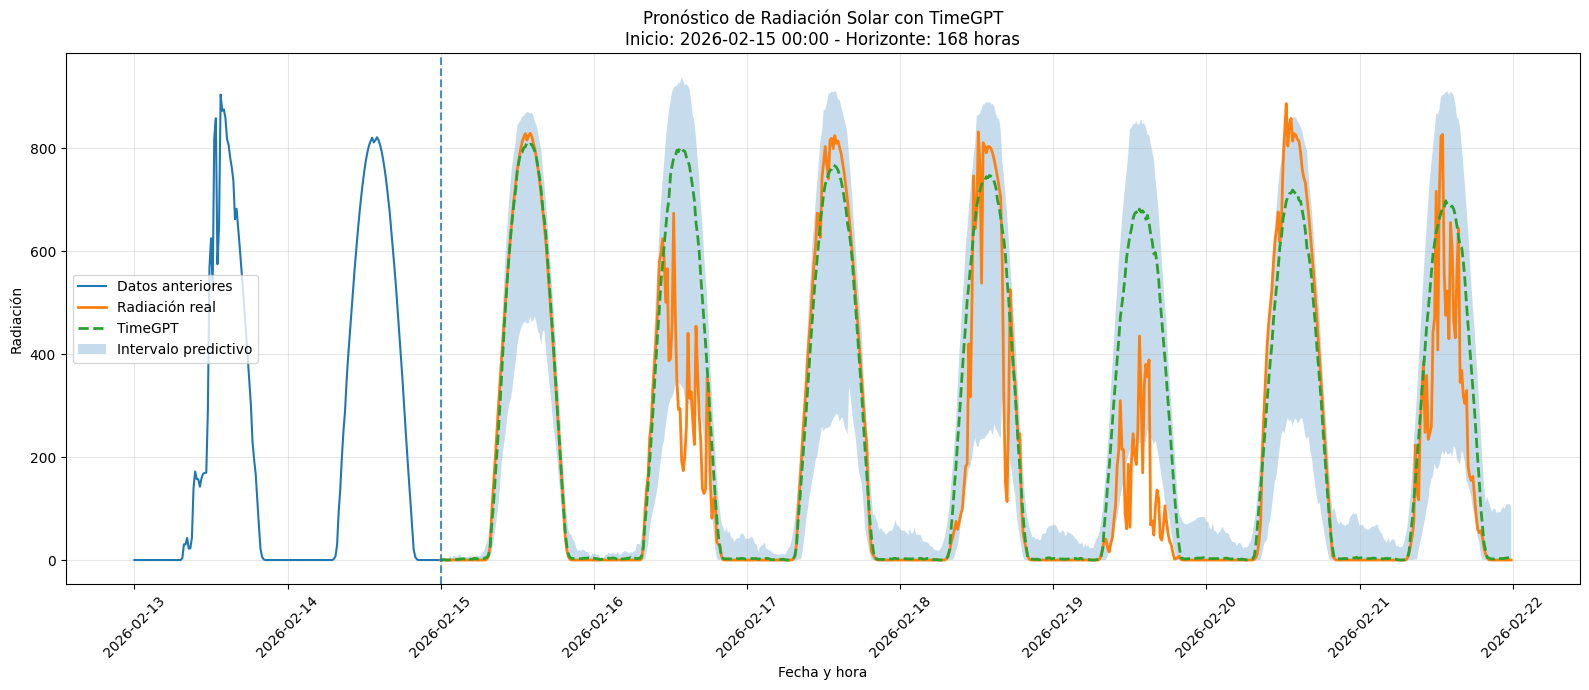

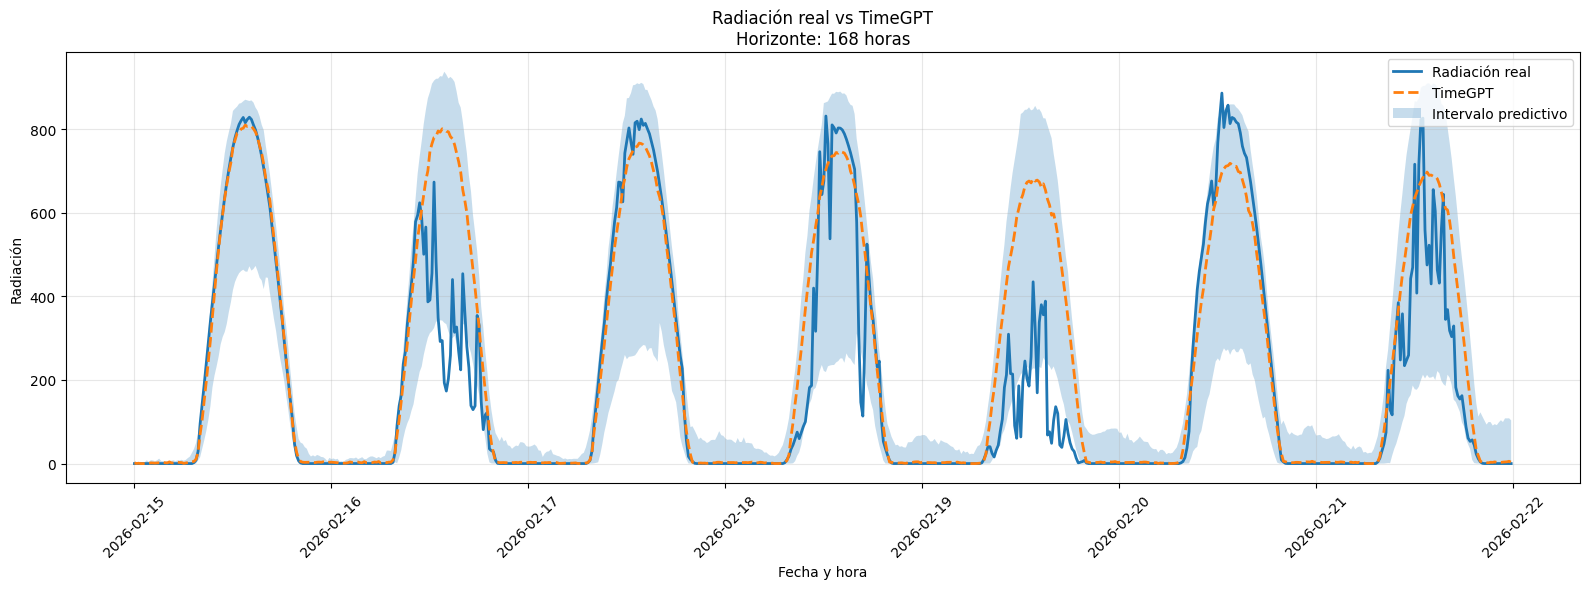

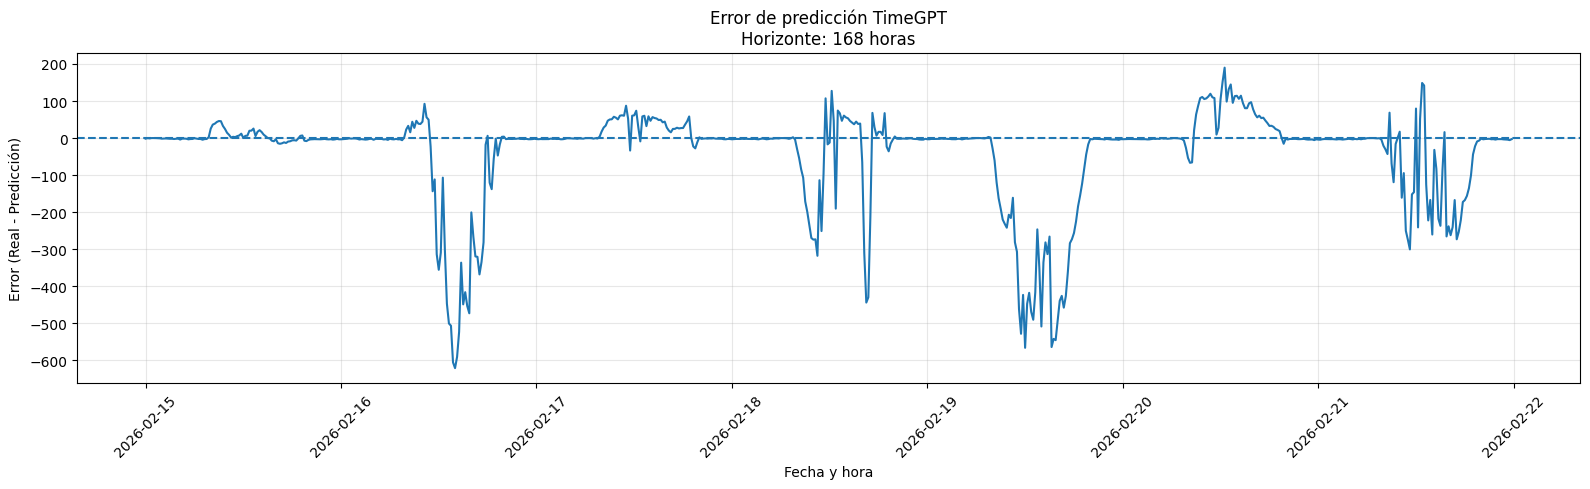



EXPERIMENTO FINALIZADO

Carpeta: resultados_timegpt_2026-02-15_00-00_168h

Archivos generados:
1. pronosticos.csv
2. metricas.csv
3. resumen_experimento.txt
4. 01_pronostico_completo.png
5. 02_real_vs_prediccion.png
6. 03_error_prediccion.png

Métricas finales:
MAE   = 66.3560
RMSE  = 138.5613
sMAPE = 113.11%
WAPE  = 33.68%

Proceso terminado.


In [4]:

# ============================================================
# 30. UNIR REAL Y PREDICCIÓN POR FECHA
# ============================================================

resultado = resultado.merge(

    forecast,

    on="ds",

    how="left"

)


resultado = resultado.rename(

    columns={
        pred_col:
            "prediccion"
    }

)


# ============================================================
# 31. COMPROBAR PRONÓSTICOS FALTANTES
# ============================================================

faltantes_pred = resultado[
    "prediccion"
].isna().sum()


print(
    "\nPredicciones faltantes:",
    faltantes_pred
)


if faltantes_pred > 0:

    raise ValueError(
        "Existen fechas del test sin "
        "predicción de TimeGPT."
    )


# ============================================================
# 32. CALCULAR ERROR
# ============================================================

resultado[
    "error"
] = (

    resultado["real"]

    -

    resultado["prediccion"]

)


resultado[
    "error_absoluto"
] = np.abs(

    resultado["error"]

)


# ============================================================
# 33. MÉTRICAS
# ============================================================

y_true = resultado[
    "real"
].to_numpy()


y_pred = resultado[
    "prediccion"
].to_numpy()


# ------------------------------------------------------------
# MAE
# ------------------------------------------------------------

MAE = mean_absolute_error(

    y_true,

    y_pred

)


# ------------------------------------------------------------
# RMSE
# ------------------------------------------------------------

RMSE = np.sqrt(

    mean_squared_error(

        y_true,

        y_pred

    )

)


# ------------------------------------------------------------
# sMAPE
# ------------------------------------------------------------

denominador = (

    np.abs(y_true)

    +

    np.abs(y_pred)

)


mask_smape = denominador > 0


if mask_smape.any():

    SMAPE = (

        100

        *

        np.mean(

            2

            *

            np.abs(

                y_true[mask_smape]

                -

                y_pred[mask_smape]

            )

            /

            denominador[mask_smape]

        )

    )

else:

    SMAPE = np.nan


# ------------------------------------------------------------
# WAPE
# ------------------------------------------------------------

suma_real = np.sum(
    np.abs(y_true)
)


if suma_real > 0:

    WAPE = (

        100

        *

        np.sum(

            np.abs(

                y_true

                -

                y_pred

            )

        )

        /

        suma_real

    )

else:

    WAPE = np.nan


# ============================================================
# 34. MOSTRAR MÉTRICAS
# ============================================================

print("\n")
print("=" * 65)
print("RESULTADOS TIMEGPT")
print("=" * 65)


print(
    "Período:"
)


print(
    resultado["ds"].min(),
    "->",
    resultado["ds"].max()
)


print(
    f"\nHorizonte: "
    f"{HORAS_PREDICCION} horas"
)


print(
    f"MAE   : {MAE:.4f}"
)


print(
    f"RMSE  : {RMSE:.4f}"
)


print(
    f"sMAPE : {SMAPE:.2f}%"
)


print(
    f"WAPE  : {WAPE:.2f}%"
)


# ============================================================
# 35. TABLA DE MÉTRICAS
# ============================================================

metricas = pd.DataFrame({

    "Modelo": [
        "TimeGPT"
    ],

    "Variable": [
        "Radiacion"
    ],

    "Fecha_inicio": [
        fecha_inicio
    ],

    "Fecha_fin": [
        fecha_fin
    ],

    "Dias_contexto": [
        DIAS_CONTEXTO
    ],

    "Horizonte_horas": [
        HORAS_PREDICCION
    ],

    "Horizonte_pasos": [
        H
    ],

    "MAE": [
        MAE
    ],

    "RMSE": [
        RMSE
    ],

    "sMAPE": [
        SMAPE
    ],

    "WAPE": [
        WAPE
    ]

})


print("\nTabla de métricas:")

print(
    metricas
)


# ============================================================
# 36. CREAR CARPETA PARA EL EXPERIMENTO
# ============================================================

fecha_nombre = fecha_inicio.strftime(
    "%Y-%m-%d_%H-%M"
)


nombre_carpeta = (

    f"resultados_timegpt_"

    f"{fecha_nombre}_"

    f"{HORAS_PREDICCION}h"

)


os.makedirs(

    nombre_carpeta,

    exist_ok=True

)


print(
    "\nCarpeta de resultados:",
    nombre_carpeta
)


# ============================================================
# 37. GUARDAR CSV DE PRONÓSTICOS
# ============================================================

resultado.to_csv(

    os.path.join(
        nombre_carpeta,
        "pronosticos.csv"
    ),

    index=False

)


# ============================================================
# 38. GUARDAR MÉTRICAS
# ============================================================

metricas.to_csv(

    os.path.join(
        nombre_carpeta,
        "metricas.csv"
    ),

    index=False

)


# ============================================================
# 39. IDENTIFICAR INTERVALOS DE TIMEGPT
# ============================================================

lower_cols = [

    c for c in resultado.columns

    if "lo-" in c.lower()

]


upper_cols = [

    c for c in resultado.columns

    if "hi-" in c.lower()

]


if lower_cols and upper_cols:

    lower_col = lower_cols[0]

    upper_col = upper_cols[0]

    tiene_intervalo = True

    print(
        "\nIntervalo encontrado:"
    )

    print(
        lower_col,
        "-",
        upper_col
    )

else:

    tiene_intervalo = False

    print(
        "\nTimeGPT no devolvió "
        "columnas de intervalo."
    )


# ============================================================
# 40. GRÁFICO 1
# CONTEXTO + REAL + PRONÓSTICO
# ============================================================

# Mostramos solamente 48 horas previas
# para que el gráfico sea legible.

fecha_contexto_grafico = (

    fecha_inicio

    -

    pd.Timedelta(
        hours=48
    )

)


contexto_grafico = df[

    (df[COLUMNA_FECHA] >= fecha_contexto_grafico)

    &

    (df[COLUMNA_FECHA] < fecha_inicio)

]


plt.figure(
    figsize=(16, 7)
)


plt.plot(

    contexto_grafico[COLUMNA_FECHA],

    contexto_grafico[COLUMNA_OBJETIVO],

    label="Datos anteriores"

)


plt.plot(

    resultado["ds"],

    resultado["real"],

    label="Radiación real",

    linewidth=2

)


plt.plot(

    resultado["ds"],

    resultado["prediccion"],

    label="TimeGPT",

    linewidth=2,

    linestyle="--"

)


if tiene_intervalo:

    plt.fill_between(

        resultado["ds"],

        resultado[lower_col],

        resultado[upper_col],

        alpha=0.25,

        label="Intervalo predictivo"

    )


plt.axvline(

    fecha_inicio,

    linestyle="--",

    alpha=0.8

)


plt.title(

    "Pronóstico de Radiación Solar con TimeGPT\n"

    f"Inicio: {fecha_inicio:%Y-%m-%d %H:%M} - "

    f"Horizonte: {HORAS_PREDICCION} horas"

)


plt.xlabel(
    "Fecha y hora"
)


plt.ylabel(
    "Radiación"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.savefig(

    os.path.join(
        nombre_carpeta,
        "01_pronostico_completo.png"
    ),

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 41. GRÁFICO 2
# REAL VS TIMEGPT
# ============================================================

plt.figure(
    figsize=(16, 6)
)


plt.plot(

    resultado["ds"],

    resultado["real"],

    label="Radiación real",

    linewidth=2

)


plt.plot(

    resultado["ds"],

    resultado["prediccion"],

    label="TimeGPT",

    linewidth=2,

    linestyle="--"

)


if tiene_intervalo:

    plt.fill_between(

        resultado["ds"],

        resultado[lower_col],

        resultado[upper_col],

        alpha=0.25,

        label="Intervalo predictivo"

    )


plt.title(

    "Radiación real vs TimeGPT\n"

    f"Horizonte: {HORAS_PREDICCION} horas"

)


plt.xlabel(
    "Fecha y hora"
)


plt.ylabel(
    "Radiación"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.savefig(

    os.path.join(
        nombre_carpeta,
        "02_real_vs_prediccion.png"
    ),

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 42. GRÁFICO 3
# ERROR DE PREDICCIÓN
# ============================================================

plt.figure(
    figsize=(16, 5)
)


plt.plot(

    resultado["ds"],

    resultado["error"],

    linewidth=1.5

)


plt.axhline(

    y=0,

    linestyle="--"

)


plt.title(

    "Error de predicción TimeGPT\n"

    f"Horizonte: {HORAS_PREDICCION} horas"

)


plt.xlabel(
    "Fecha y hora"
)


plt.ylabel(
    "Error (Real - Predicción)"
)


plt.grid(
    alpha=0.3
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.savefig(

    os.path.join(
        nombre_carpeta,
        "03_error_prediccion.png"
    ),

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 43. CREAR ARCHIVO TXT RESUMEN
# ============================================================

ruta_resumen = os.path.join(

    nombre_carpeta,

    "resumen_experimento.txt"

)


with open(

    ruta_resumen,

    "w",

    encoding="utf-8"

) as f:

    f.write(
        "RESULTADOS TIMEGPT\n"
    )

    f.write(
        "=" * 50 + "\n\n"
    )

    f.write(
        "Variable: Radiación solar\n"
    )

    f.write(
        f"Fecha inicio: "
        f"{fecha_inicio}\n"
    )

    f.write(
        f"Fecha fin: "
        f"{fecha_fin}\n"
    )

    f.write(
        f"Frecuencia: "
        f"{FREQ}\n"
    )

    f.write(
        f"Contexto: "
        f"{DIAS_CONTEXTO} días\n"
    )

    f.write(
        f"Horizonte: "
        f"{HORAS_PREDICCION} horas\n"
    )

    f.write(
        f"Pasos: "
        f"{H}\n\n"
    )

    f.write(
        "MÉTRICAS\n"
    )

    f.write(
        "-" * 30 + "\n"
    )

    f.write(
        f"MAE: "
        f"{MAE:.4f}\n"
    )

    f.write(
        f"RMSE: "
        f"{RMSE:.4f}\n"
    )

    f.write(
        f"sMAPE: "
        f"{SMAPE:.2f}%\n"
    )

    f.write(
        f"WAPE: "
        f"{WAPE:.2f}%\n"
    )


# ============================================================
# 44. RESULTADO FINAL
# ============================================================

print("\n")
print("=" * 65)
print("EXPERIMENTO FINALIZADO")
print("=" * 65)


print(
    "\nCarpeta:",
    nombre_carpeta
)


print(
    "\nArchivos generados:"
)


print(
    "1. pronosticos.csv"
)


print(
    "2. metricas.csv"
)


print(
    "3. resumen_experimento.txt"
)


print(
    "4. 01_pronostico_completo.png"
)


print(
    "5. 02_real_vs_prediccion.png"
)


print(
    "6. 03_error_prediccion.png"
)


print("\nMétricas finales:")

print(
    f"MAE   = {MAE:.4f}"
)

print(
    f"RMSE  = {RMSE:.4f}"
)

print(
    f"sMAPE = {SMAPE:.2f}%"
)

print(
    f"WAPE  = {WAPE:.2f}%"
)

print("\nProceso terminado.")